<!-- Dr. Nam H. Le. drnamlabs.com, bunnyquant.com -->
# 05. Finite-size scaling: how sharp is the transition, and of what order?

**Order parameter.** Let p be the fraction of stored points on the + side. Then **φ = |2p − 1|**.
- φ ≈ 0: both kinds of data are remembered (symmetric, alive).
- φ → 1: the memory holds only one kind (consensus, collapsed).

*Example.* K = 80 with 60 points on the left and 20 on the right gives p = 0.25 and φ = 0.5.

From the time series of φ in each run we compute three quantities.
- **Susceptibility χ = K(⟨φ²⟩ − ⟨φ⟩²).** It measures how much φ fluctuates. It peaks at the transition and grows with K.
- **Binder cumulant U = 1 − ⟨φ⁴⟩ / (3⟨φ²⟩²).** At a continuous transition the curves for different K cross at one point.
  A deep **negative** dip means two coexisting states, which is the signature of a **first-order** transition.
- **The distribution of φ itself.** One hump means a continuous transition. Two humps means first order.

Data: `sweep_fss.py` (β ∈ {1.5, 2, 3}, K = 20 to 320) and `sweep_order.py` (β = 2, fine α grid, K = 80 to 640, two starts).

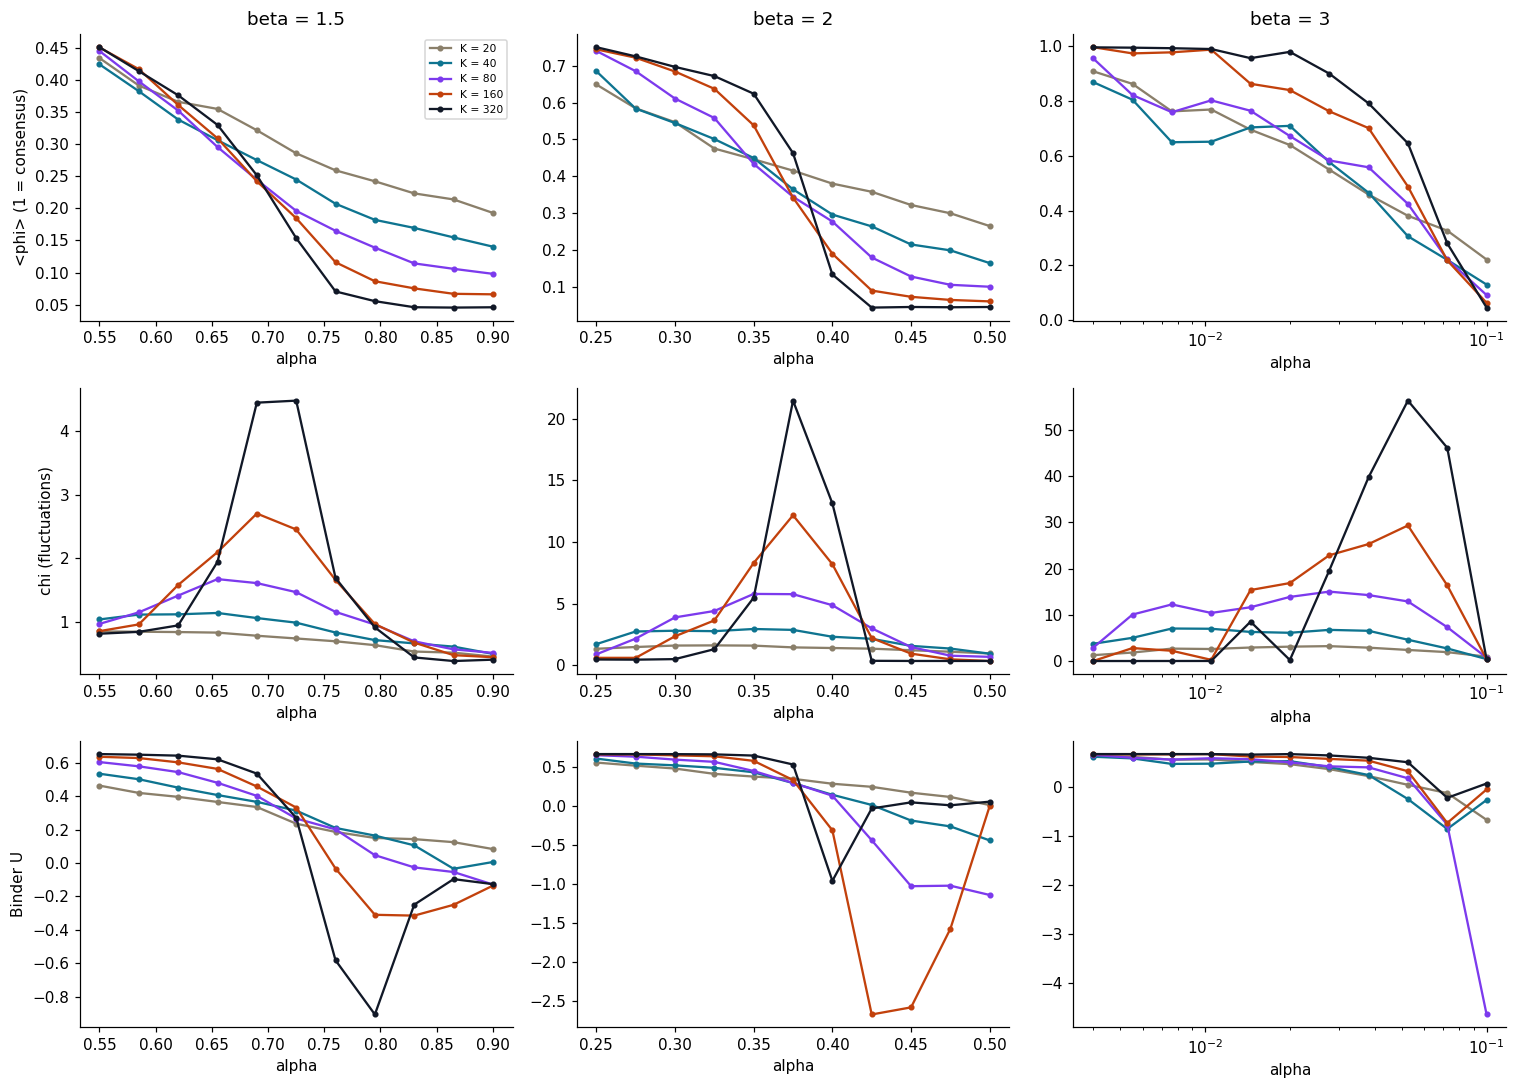

In [1]:
# Dr. Nam H. Le. drnamlabs.com, bunnyquant.com
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
FIG = Path('figures')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
z = np.load('data/sweep_fss.npz')
Ks, betas, AL = z['Ks'], z['betas'], z['alphas']
m1, m2, m4 = [z[k].mean(-1) for k in ('m1', 'm2', 'm4')]
U = 1 - m4 / (3 * m2 ** 2)
chi = Ks[:, None, None] * (m2 - m1 ** 2)
cols = {20: '#8a7f6a', 40: '#0e7490', 80: '#7c3aed', 160: '#c2410c', 320: '#111827', 640: '#b45309'}
fig, ax = plt.subplots(3, 3, figsize=(14, 10))
for bi, b in enumerate(betas):
    for ki, K in enumerate(Ks):
        kw = dict(color=cols[int(K)], marker='o', ms=3, label=f'K = {int(K)}')
        ax[0, bi].plot(AL[bi], m1[ki, bi], **kw)
        ax[1, bi].plot(AL[bi], chi[ki, bi], **kw)
        ax[2, bi].plot(AL[bi], U[ki, bi], **kw)
    ax[0, bi].set_title(f'beta = {b:g}')
    for r in range(3):
        if b == 3.0:
            ax[r, bi].set_xscale('log')
        ax[r, bi].set_xlabel('alpha')
ax[0, 0].set_ylabel('<phi> (1 = consensus)'); ax[1, 0].set_ylabel('chi (fluctuations)'); ax[2, 0].set_ylabel('Binder U')
ax[0, 0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'nb05_fss.png'); plt.show()

beta=1.5: chi_max [0.8 1.1 1.7 2.7 4.5]  slope 0.61  peak at alpha [0.55  0.655 0.655 0.69  0.725]
beta=2: chi_max [ 1.6  2.9  5.8 12.2 21.5]  slope 0.95  peak at alpha [0.325 0.35  0.35  0.375 0.375]
beta=3: chi_max [ 3.2  7.  15.  29.3 56.3]  slope 1.03  peak at alpha [0.028 0.008 0.028 0.053 0.053]


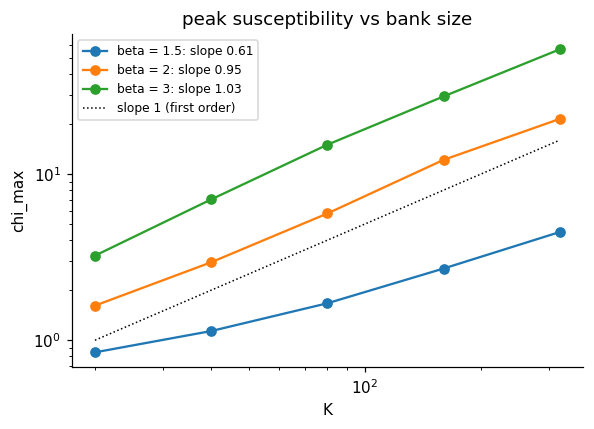

In [2]:
# how fast does the chi peak grow with K?  first order: chi_max ~ K;  continuous: chi_max ~ K^(gamma/nu) < K
fig, ax = plt.subplots(figsize=(5.5, 4))
for bi, b in enumerate(betas):
    cm = chi[:, bi].max(1)
    s = np.polyfit(np.log(Ks), np.log(cm), 1)[0]
    ax.plot(Ks, cm, 'o-', label=f'beta = {b:g}: slope {s:.2f}')
    print(f'beta={b:g}: chi_max', np.round(cm, 1), ' slope', round(s, 2), ' peak at alpha', np.round(AL[bi][chi[:, bi].argmax(1)], 3))
ax.plot([20, 320], [1, 16], 'k:', lw=1, label='slope 1 (first order)')
ax.set(xscale='log', yscale='log', xlabel='K', ylabel='chi_max', title='peak susceptibility vs bank size')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'nb05_chimax.png'); plt.show()

## The order of the transition (β = 2, fine grid, K up to 640)

For each α and K we plot the histogram of φ, pooling all seeds over the second half of each run.
The two starts are shown separately: blue starts symmetric (alive), red starts in consensus.
If the two starts end in different places at large K, that is hysteresis.

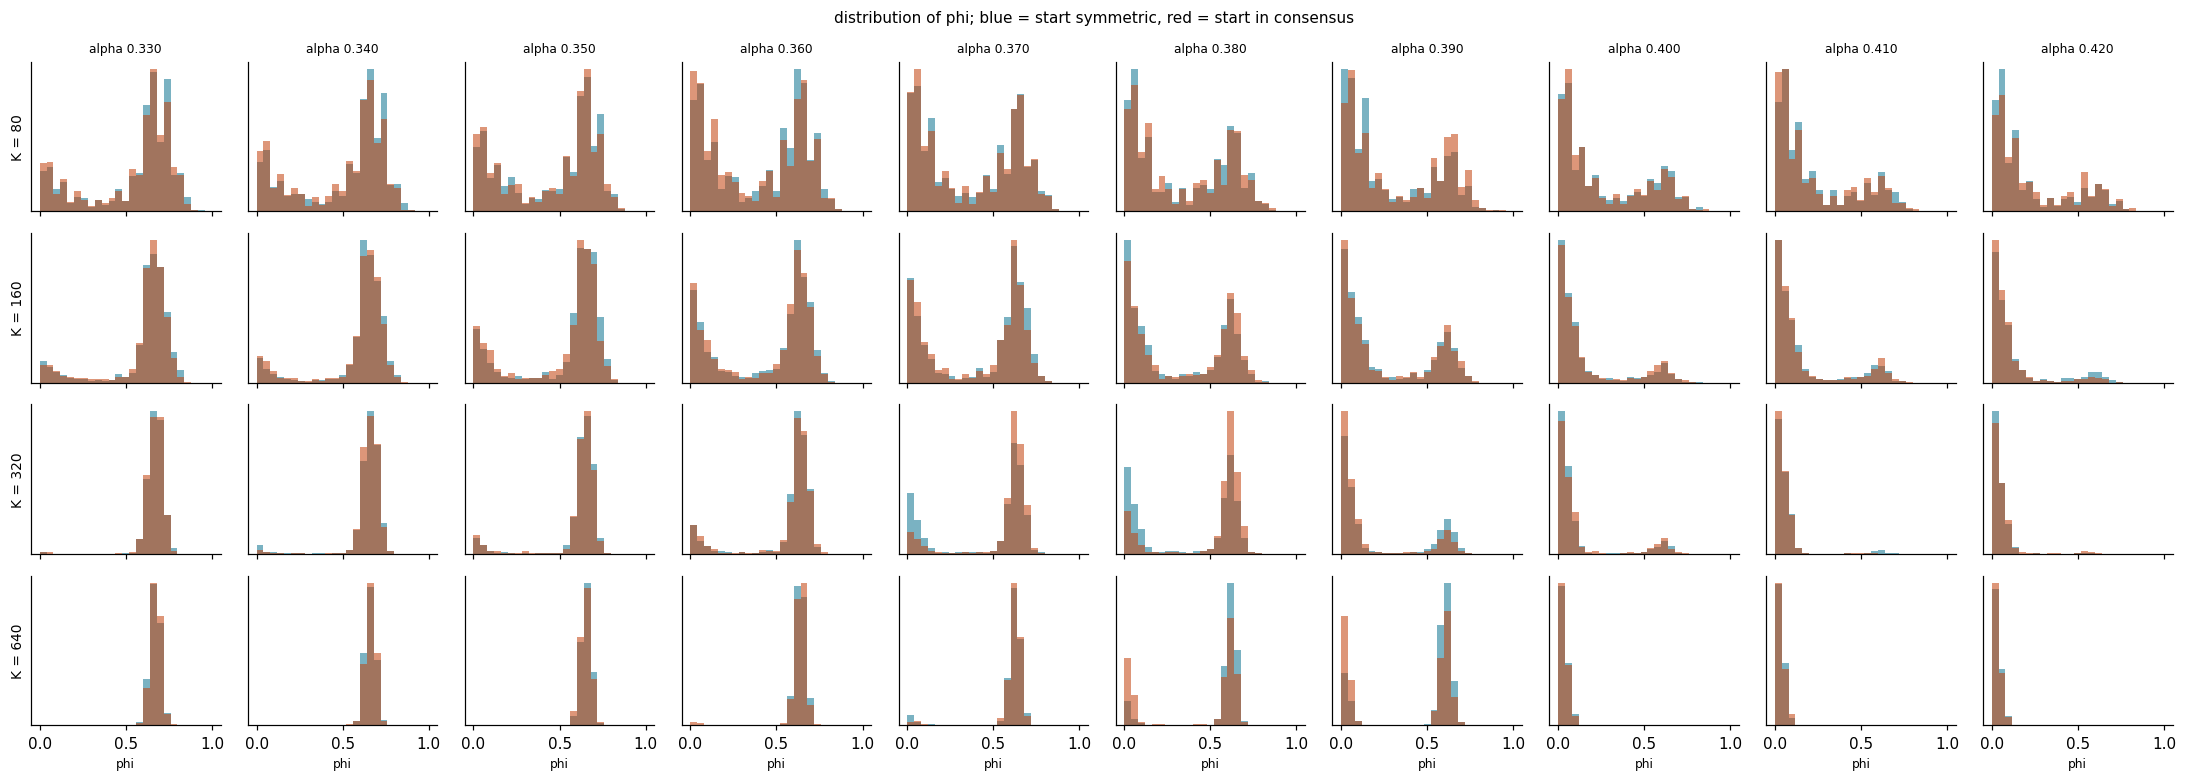

mean phi  (sym start | cons start)
K=  80 sym  [0.55 0.51 0.46 0.41 0.37 0.34 0.28 0.27 0.23 0.21]
       cons [0.53 0.48 0.45 0.37 0.37 0.34 0.32 0.25 0.23 0.24]
K= 160 sym  [0.6  0.6  0.54 0.45 0.43 0.31 0.26 0.15 0.16 0.13]
       cons [0.6  0.58 0.52 0.44 0.41 0.35 0.27 0.17 0.16 0.1 ]
K= 320 sym  [0.67 0.64 0.61 0.56 0.47 0.38 0.23 0.11 0.07 0.05]
       cons [0.66 0.65 0.6  0.56 0.56 0.51 0.16 0.13 0.05 0.06]
K= 640 sym  [0.67 0.66 0.65 0.64 0.6  0.56 0.49 0.03 0.03 0.03]
       cons [0.67 0.66 0.65 0.63 0.61 0.43 0.37 0.03 0.03 0.03]
alphas [0.33 0.34 0.35 0.36 0.37 0.38 0.39 0.4  0.41 0.42]


In [3]:
o = np.load('data/sweep_order.npz')
KO, AO = o['Ks'], o['alphas']
def series(K, ai, st):
    return [o[k] for k in o.files if k.startswith(f'K{K}_a{ai}_{st}_')]
fig, ax = plt.subplots(len(KO), len(AO), figsize=(2.0 * len(AO), 1.8 * len(KO)), sharex=True)
bins = np.linspace(0, 1, 26)
for r, K in enumerate(KO):
    for c in range(len(AO)):
        for st, col in (('sym', '#0e7490'), ('cons', '#c2410c')):
            v = np.concatenate(series(K, c, st))
            ax[r, c].hist(v, bins=bins, color=col, alpha=0.55, density=True)
        ax[r, c].set_yticks([])
        if r == 0: ax[r, c].set_title(f'alpha {AO[c]:.3f}', fontsize=8)
        if c == 0: ax[r, c].set_ylabel(f'K = {int(K)}', fontsize=9)
for c in range(len(AO)): ax[-1, c].set_xlabel('phi', fontsize=8)
fig.suptitle('distribution of phi; blue = start symmetric, red = start in consensus', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'nb05_phi_hist.png'); plt.show()

print('mean phi  (sym start | cons start)')
for K in KO:
    s = [np.mean(np.concatenate(series(K, c, 'sym'))) for c in range(len(AO))]
    t = [np.mean(np.concatenate(series(K, c, 'cons'))) for c in range(len(AO))]
    print(f'K={int(K):4d} sym ', np.round(s, 2)); print(f'       cons', np.round(t, 2))
print('alphas', AO)

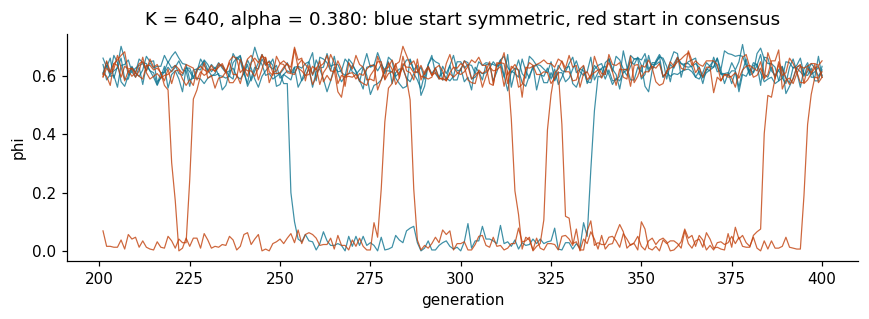

In [4]:
# example time series at the alpha where the starts disagree most, largest K
K = int(KO[-1])
gap = [abs(np.mean(np.concatenate(series(K, c, 'sym'))) - np.mean(np.concatenate(series(K, c, 'cons')))) for c in range(len(AO))]
c = int(np.argmax(gap))
fig, ax = plt.subplots(figsize=(8, 3))
for st, col in (('sym', '#0e7490'), ('cons', '#c2410c')):
    for v in series(K, c, st):
        ax.plot(np.arange(len(v)) + 201, v, color=col, lw=0.8, alpha=0.8)
ax.set(xlabel='generation', ylabel='phi', title=f'K = {K}, alpha = {AO[c]:.3f}: blue start symmetric, red start in consensus')
fig.tight_layout(); fig.savefig(FIG / 'nb05_timeseries.png'); plt.show()

## Reading

**The consensus transition is FIRST ORDER.**

1. **phi is bimodal, with one peak at 0 (symmetric) and one at ~0.62 (consensus).** The consensus peak sits exactly at phi = 1 - alpha: every self-written point is on one side, while the fresh points stay balanced. The jump in phi (~0.6) does NOT shrink as K grows. The order parameter is discontinuous.
2. **The coexistence window narrows with K.** Both peaks appear over alpha = 0.33-0.42 at K = 80, but only over 0.38-0.39 at K = 640. alpha_c(beta = 2) ~ 0.385.
3. **The susceptibility peak grows in proportion to K** (slope 0.95 at beta = 2 and 1.03 at beta = 3). That is volume scaling, as expected for first order. beta = 1.5 has slope 0.61 and is probably not yet asymptotic.
4. **Telegraph switching** (`nb05_timeseries.png`): at K = 640, alpha = 0.38, each run jumps between the two states with dwell times of tens to hundreds of generations. Both starts switch, so no lasting hysteresis is seen within 200 generations. For a first-order transition, dwell times should grow exponentially with K, and hysteresis appears only once they exceed the run. Not yet measured.
5. **Correction to notebooks 01 and 02.** The mean-field bistability is NOT an artifact. It is the coexistence of a first-order transition. The small banks (K = 20-80) used for the hysteresis test switch too fast to show it. The two-population mean field put the keep-alive edge at 0.39, and the true coexistence point is ~0.385.